In [1]:
from pathlib import Path
import sys
import csv
import numpy as np
import matplotlib.pyplot as plt

REPO = Path("/Users/jadechng/Desktop/HomeStretch/HomeStretchRepo")

OLD_FILE = REPO / "Data/Raw/Typical/001_BicepCurl_R_T.csv"

NEW_FILE = Path(
    "/Users/jadechng/Desktop/HomeStretch/recordings/1005/"
    "Anisha Bicep Curls_20261005-115528_1d1d07ea.csv"
)

# New recording: first wearing period, before removing the watch.
NEW_WINDOW = (0, 32)

# The old logger's pitch/yaw/roll are assumed to be in radians.
OLD_ANGLES_IN_RADIANS = True

sys.path.insert(0, str(REPO / "signal-processing"))
from session_pipeline.reader import load_recording
from session_pipeline.orientation import estimate

In [2]:
# OLD RECORDING
with OLD_FILE.open(newline="") as f:
    rows = list(csv.DictReader(f))

old_time = np.array([float(row["seconds_elapsed"]) for row in rows])
old_time -= old_time[0]

old_angles = np.array([
    [float(row["pitch"]), float(row["yaw"]), float(row["roll"])]
    for row in rows
])

if OLD_ANGLES_IN_RADIANS:
    old_angles = np.rad2deg(old_angles)

# Remove artificial jumps at ±180°.
old_angles = np.rad2deg(
    np.unwrap(np.deg2rad(old_angles), axis=0)
)

# NEW RECORDING
new_recording = load_recording(NEW_FILE)

def crop(stream, window):
    keep = (
        (stream[:, 0] >= window[0])
        & (stream[:, 0] <= window[1])
    )
    return stream[keep]

accel = crop(new_recording["streams"]["acceleration"], NEW_WINDOW)
gyro = crop(new_recording["streams"]["gyroscope"], NEW_WINDOW)

new_blocks, diagnostics = estimate(accel, gyro, fs=50.0)

if not new_blocks:
    raise ValueError("No usable orientation data in NEW_WINDOW.")

print("New orientation blocks:", len(new_blocks))
print("Calibration:", diagnostics["calibration"])

New orientation blocks: 1
Calibration: first_two_seconds_stationary


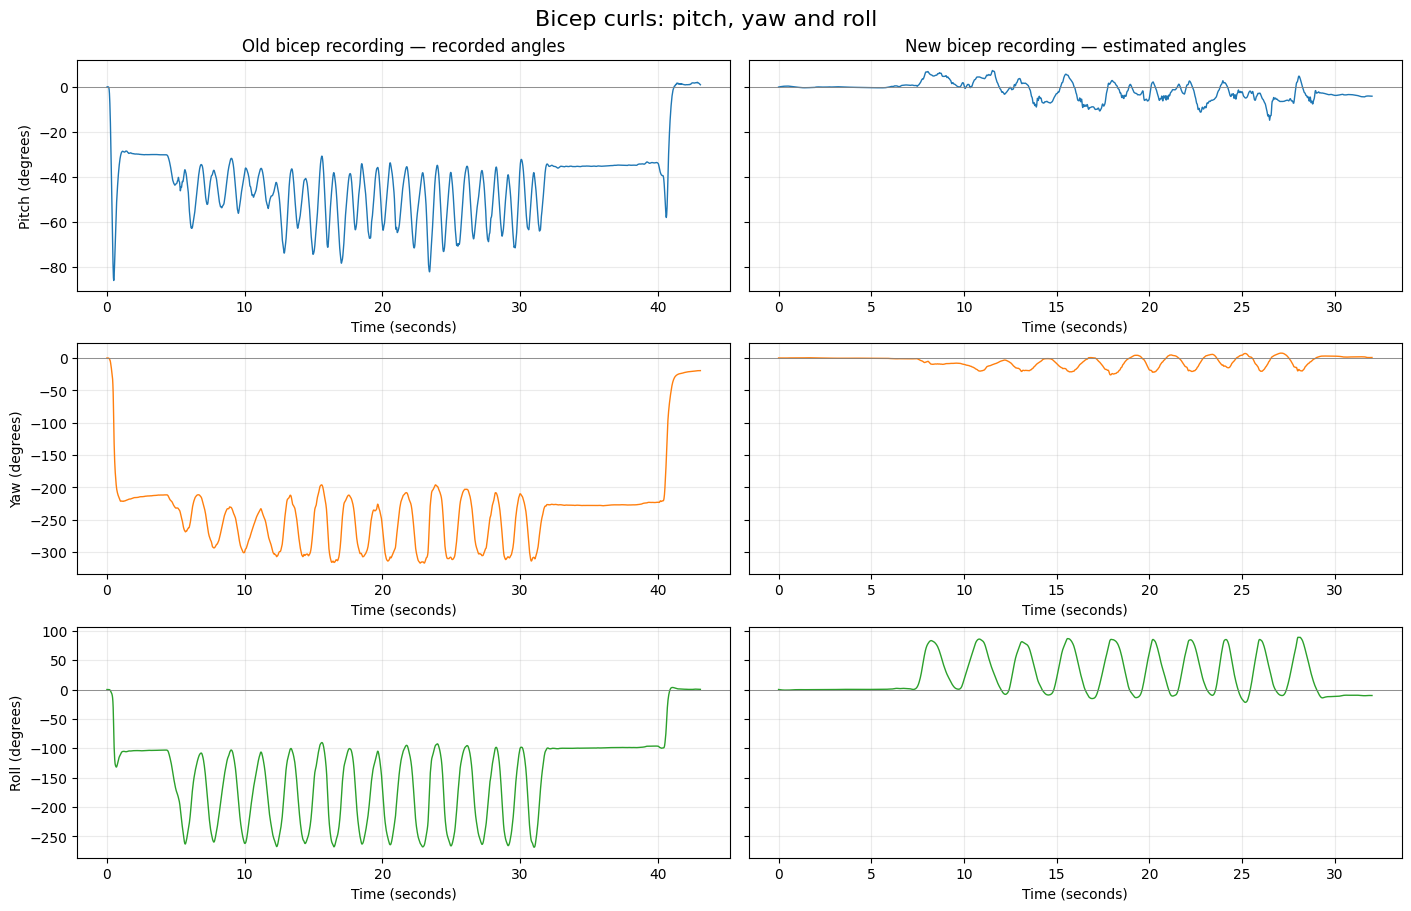

In [3]:
CHANNELS = ["Pitch", "Yaw", "Roll"]
COLORS = ["tab:blue", "tab:orange", "tab:green"]

# True removes the starting offset for visual comparison.
# It does NOT align the devices' anatomical axes.
REMOVE_START_OFFSET = True

old_plot = old_angles.copy()
if REMOVE_START_OFFSET:
    old_plot -= old_plot[0]

fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 9),
    sharey="row",
    constrained_layout=True
)

for channel, (name, color) in enumerate(zip(CHANNELS, COLORS)):
    # Old recording
    axes[channel, 0].plot(
        old_time,
        old_plot[:, channel],
        color=color,
        linewidth=1
    )

    # New recording: draw blocks separately to avoid joining gaps.
    for block in new_blocks:
        angles = block["angles"].copy()  # pitch, yaw, roll in degrees

        if REMOVE_START_OFFSET:
            angles -= angles[0]

        axes[channel, 1].plot(
            block["time"] - NEW_WINDOW[0],
            angles[:, channel],
            color=color,
            linewidth=1
        )

    axes[channel, 0].set_ylabel(f"{name} (degrees)")

    for ax in axes[channel]:
        ax.grid(alpha=0.25)
        ax.axhline(0, color="gray", linewidth=0.6)
        ax.set_xlabel("Time (seconds)")

axes[0, 0].set_title("Old bicep recording — recorded angles")
axes[0, 1].set_title("New bicep recording — estimated angles")

fig.suptitle("Bicep curls: pitch, yaw and roll", fontsize=16)
plt.show()

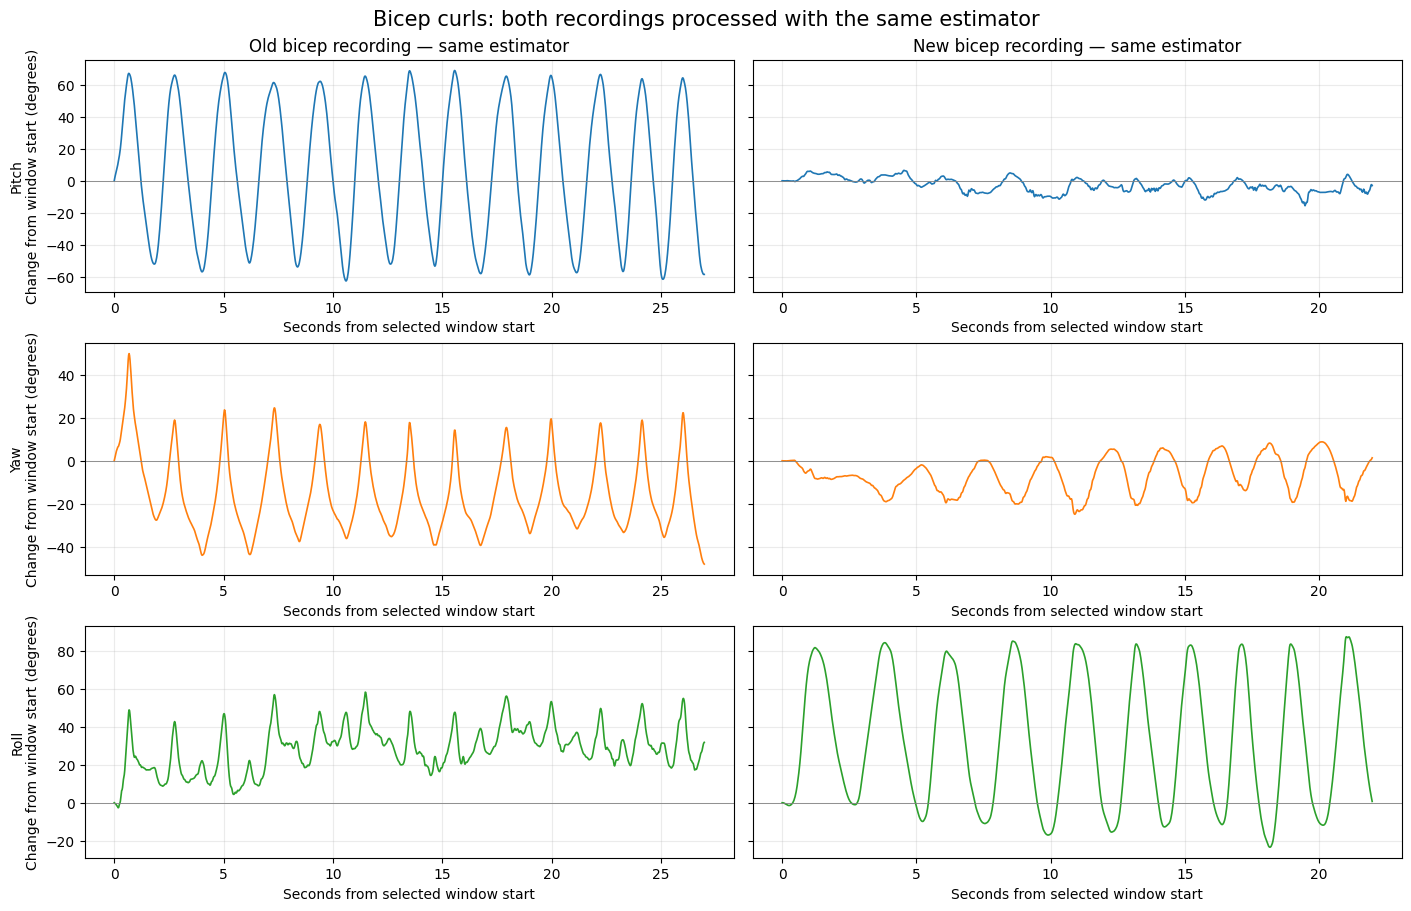

Old calibration: no_stationary_baseline; bias not corrected
New calibration: first_two_seconds_stationary
Same estimator does not yet mean matching sensor mounting axes.


In [4]:
# Compare OLD and NEW using the SAME orientation estimator.
# Uses OLD_FILE, NEW_FILE, load_recording, and estimate from earlier cells.

OLD_EXERCISE = (5.0, 32.0)
NEW_EXERCISE = (7.0, 29.0)

OLD_GYRO_IN_RADIANS = True
OLD_ACCEL_SIGN = -1.0

# ---------- Load old raw sensor data ----------
with OLD_FILE.open(newline="") as f:
    old_rows = list(csv.DictReader(f))

t_old = np.array([
    float(row["seconds_elapsed"]) for row in old_rows
])
t_old -= t_old[0]

gravity_old = np.array([
    [float(row[f"gravity{axis}"]) for axis in "XYZ"]
    for row in old_rows
])

user_accel_old = np.array([
    [float(row[f"acceleration{axis}"]) for axis in "XYZ"]
    for row in old_rows
])

gyro_old = np.array([
    [float(row[f"rotationRate{axis}"]) for axis in "XYZ"]
    for row in old_rows
])

if OLD_GYRO_IN_RADIANS:
    gyro_old = np.rad2deg(gyro_old)

# Reconstruct total acceleration, then apply the declared sign convention.
accel_old = OLD_ACCEL_SIGN * (gravity_old + user_accel_old)

# Estimator input: time, x, y, z, validity.
def make_stream(t, xyz):
    valid = np.isfinite(xyz).all(axis=1).astype(float)
    return np.column_stack([t, xyz, valid])

old_accel_stream = make_stream(t_old, accel_old)
old_gyro_stream = make_stream(t_old, gyro_old)

# ---------- Load new raw sensor data ----------
new_record = load_recording(NEW_FILE)
new_accel_stream = new_record["streams"]["acceleration"]
new_gyro_stream = new_record["streams"]["gyroscope"]

# Keep the lead-in for initialization; stop before later handling.
def through_end(stream, end):
    return stream[stream[:, 0] <= end].copy()

old_blocks, old_info = estimate(
    through_end(old_accel_stream, OLD_EXERCISE[1]),
    through_end(old_gyro_stream, OLD_EXERCISE[1]),
    fs=50.0,
)

new_blocks, new_info = estimate(
    through_end(new_accel_stream, NEW_EXERCISE[1]),
    through_end(new_gyro_stream, NEW_EXERCISE[1]),
    fs=50.0,
)

if not old_blocks or not new_blocks:
    raise ValueError("No usable orientation blocks for one of the recordings.")

# ---------- Plot the exercise intervals ----------
fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 9),
    sharey="row",
    constrained_layout=True,
)

channel_names = ["Pitch", "Yaw", "Roll"]
colors = ["tab:blue", "tab:orange", "tab:green"]

for column, (blocks, window, title) in enumerate([
    (old_blocks, OLD_EXERCISE, "Old bicep recording"),
    (new_blocks, NEW_EXERCISE, "New bicep recording"),
]):
    plotted = False

    for block in blocks:
        keep = (
            (block["time"] >= window[0])
            & (block["time"] <= window[1])
        )
        if keep.sum() < 2:
            continue

        time = block["time"][keep] - window[0]
        angles = block["angles"][keep].copy()

        # Display offset only: does not perform anatomical axis alignment.
        # Reset separately for each block; never connect across missing data.
        angles -= angles[0]
        plotted = True

        for channel, color in enumerate(colors):
            axes[channel, column].plot(
                time, angles[:, channel],
                color=color, linewidth=1.2,
            )

    if not plotted:
        raise ValueError(f"No samples inside the selected window for {title}.")

    axes[0, column].set_title(f"{title} — same estimator")

for channel, name in enumerate(channel_names):
    axes[channel, 0].set_ylabel(
        f"{name}\nChange from window start (degrees)"
    )
    for ax in axes[channel]:
        ax.grid(alpha=0.25)
        ax.axhline(0, color="gray", linewidth=0.6)
        ax.set_xlabel("Seconds from selected window start")

fig.suptitle(
    "Bicep curls: both recordings processed with the same estimator",
    fontsize=15,
)
plt.show()

print("Old calibration:", old_info["calibration"])
print("New calibration:", new_info["calibration"])
print("Same estimator does not yet mean matching sensor mounting axes.")

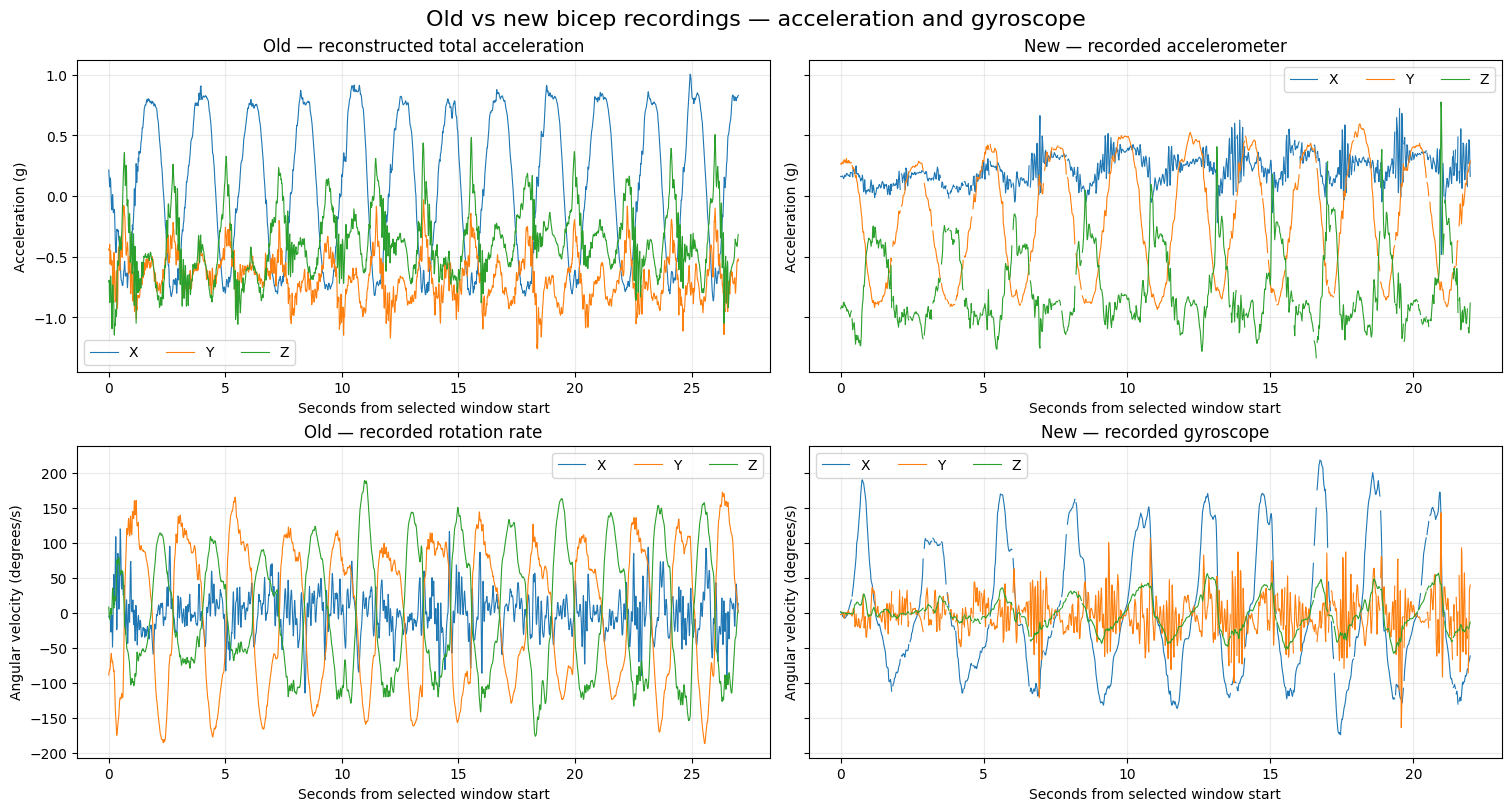

In [5]:
# OLD_FILE and NEW_FILE should point to your selected recordings.
# Requires: csv, numpy as np, matplotlib.pyplot as plt, load_recording

OLD_WINDOW = (5, 32)   # Set to None for the full recording
NEW_WINDOW = (7, 29)   # First set, excluding watch removal

OLD_GYRO_IN_RADIANS = True
OLD_ACCEL_SIGN = -1.0  # Assumed conversion to new sensor's specific-force sign

# ---------- OLD RECORDING ----------
with OLD_FILE.open(newline="") as f:
    rows = list(csv.DictReader(f))

old_t = np.array([float(r["seconds_elapsed"]) for r in rows])
old_t -= old_t[0]

old_gravity = np.array([
    [float(r[f"gravity{axis}"]) for axis in "XYZ"]
    for r in rows
])

old_user_accel = np.array([
    [float(r[f"acceleration{axis}"]) for axis in "XYZ"]
    for r in rows
])

# Reconstructed total acceleration; not an original raw hardware stream.
old_accel = OLD_ACCEL_SIGN * (old_gravity + old_user_accel)

old_gyro = np.array([
    [float(r[f"rotationRate{axis}"]) for axis in "XYZ"]
    for r in rows
])

if OLD_GYRO_IN_RADIANS:
    old_gyro = np.rad2deg(old_gyro)

# ---------- NEW RECORDING ----------
record = load_recording(NEW_FILE)

def get_new_stream(sensor):
    stream = record["streams"][sensor]
    t = stream[:, 0].copy()
    xyz = stream[:, 1:4].copy()

    # Show invalid samples and long gaps as breaks.
    xyz[stream[:, 4] == 0] = np.nan
    xyz[np.r_[False, np.diff(t) > 0.1]] = np.nan
    return t, xyz

new_accel_t, new_accel = get_new_stream("acceleration")
new_gyro_t, new_gyro = get_new_stream("gyroscope")

def select_window(t, xyz, window):
    if window is None:
        keep = np.ones(len(t), dtype=bool)
        start = t[0]
    else:
        keep = (t >= window[0]) & (t <= window[1])
        start = window[0]

    if not keep.any():
        raise ValueError(f"No samples in window {window}")

    return t[keep] - start, xyz[keep]

# ---------- PLOT ----------
fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 8),
    sharey="row",
    constrained_layout=True,
)

panels = [
    (axes[0, 0], old_t, old_accel, OLD_WINDOW,
     "Old — reconstructed total acceleration", "Acceleration (g)"),
    (axes[0, 1], new_accel_t, new_accel, NEW_WINDOW,
     "New — recorded accelerometer", "Acceleration (g)"),
    (axes[1, 0], old_t, old_gyro, OLD_WINDOW,
     "Old — recorded rotation rate", "Angular velocity (degrees/s)"),
    (axes[1, 1], new_gyro_t, new_gyro, NEW_WINDOW,
     "New — recorded gyroscope", "Angular velocity (degrees/s)"),
]

colors = ["tab:blue", "tab:orange", "tab:green"]

for ax, t, xyz, window, title, ylabel in panels:
    t_plot, xyz_plot = select_window(t, xyz, window)

    for channel, color in enumerate(colors):
        ax.plot(
            t_plot, xyz_plot[:, channel],
            color=color, label="XYZ"[channel], linewidth=0.8,
        )

    ax.set_title(title)
    ax.set_xlabel("Seconds from selected window start")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.legend(ncol=3)

fig.suptitle(
    "Old vs new bicep recordings — acceleration and gyroscope",
    fontsize=16,
)
plt.show()

Left arm: first_two_seconds_stationary | 1 blocks
Right arm: first_two_seconds_stationary | 1 blocks


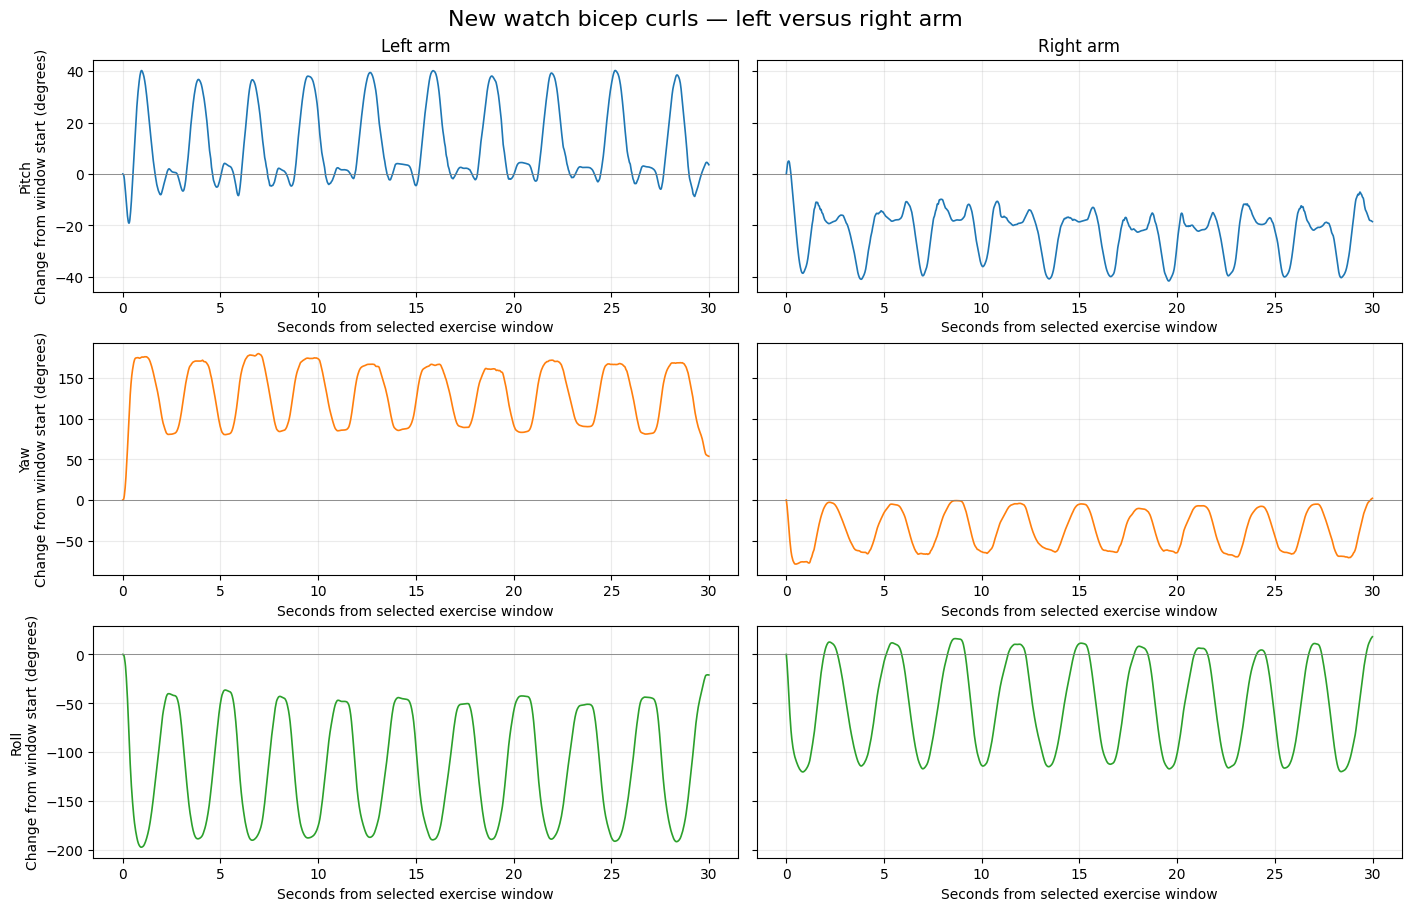

In [7]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Uses load_recording and estimate imported in your earlier cells.
DATA_DIR = Path("/Users/jadechng/Desktop/HomeStretch/recordings/1005")

recordings = {
    "Left arm": {
        "file": DATA_DIR / "ashritha bicep left_20261005-121154_15c80026.csv",
        "window": (7.0, 37.0),
    },
    "Right arm": {
        "file": DATA_DIR / "ashritha bicep right_20261005-120702_53c6c2fd.csv",
        "window": (6.0, 36.0),
    },
}

channels = ["Pitch", "Yaw", "Roll"]
colors = ["tab:blue", "tab:orange", "tab:green"]

fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 9),
    sharey="row",
    constrained_layout=True,
)

for column, (side, settings) in enumerate(recordings.items()):
    recording = load_recording(settings["file"])
    start, end = settings["window"]

    # Include the initial hold for orientation initialization.
    # Stop before removing/reattaching the watch.
    accel = recording["streams"]["acceleration"]
    gyro = recording["streams"]["gyroscope"]

    accel = accel[accel[:, 0] <= end]
    gyro = gyro[gyro[:, 0] <= end]

    blocks, info = estimate(accel, gyro, fs=50.0)

    plotted = False
    for block in blocks:
        keep = (
            (block["time"] >= start)
            & (block["time"] <= end)
        )
        if keep.sum() < 2:
            continue

        t = block["time"][keep] - start
        angles = block["angles"][keep].copy()

        # Remove starting offsets only.
        # No sign flips, axis swaps, or amplitude normalization.
        angles -= angles[0]

        for channel, color in enumerate(colors):
            axes[channel, column].plot(
                t,
                angles[:, channel],
                color=color,
                linewidth=1.2,
            )
        plotted = True

    if not plotted:
        raise ValueError(f"No usable orientation samples for {side}")

    axes[0, column].set_title(f"{side}")
    print(f"{side}: {info['calibration']} | {len(blocks)} blocks")

for channel, name in enumerate(channels):
    axes[channel, 0].set_ylabel(
        f"{name}\nChange from window start (degrees)"
    )
    for ax in axes[channel]:
        ax.axhline(0, color="gray", linewidth=0.6)
        ax.grid(alpha=0.25)
        ax.set_xlabel("Seconds from selected exercise window")

fig.suptitle(
    "New watch bicep curls — left versus right arm",
    fontsize=16,
)
plt.show()